## Portfolioaufgabe PA 4


### Lärmminderung durch eine Stellwand mit der FDTD-Methode simulieren

In dieser Aufgabe untersuchen Sie ein vereinfachtes raumakustisches Problem: Eine Schallquelle sendet in einem rechteckigen Raum einen kurzen Schallimpuls aus. An einer anderen Position wird der Schalldruck an einem Empfangsort ausgewertet. Mit der Finite-Differenzen-Methode im Zeitbereich (FDTD) simulieren Sie das zweidimensionale Schallfeld und bewerten anschließend, wie stark eine Stellwand den am Empfangsort ankommenden Schall reduziert.

Sie benötigen dafür keine Vorkenntnisse in Raumakustik oder numerischen Verfahren. Die Aufgabe führt die benötigten Begriffe schrittweise ein. Akustisch betrachten wir den Schalldruck $p(x,y,t)$: positive und negative Werte beschreiben kleine Druckschwankungen der Luft um den normalen Luftdruck. Numerisch ersetzen wir den kontinuierlichen Raum durch ein regelmäßiges Gitter und betrachten die Werte für den Schalldruck an den einzelnen Gitterpunkten. Der Schalldruck hängt vom Ort $(x,y)$ und von der Zeit $t$ ab. Die Abhängigkeit von der Zeit wird in kleinen Zeitschritten betrachtet, die vom Ort wird durch die Betrachtung an den einzelnen Gitterpunkten abgebildet.

Die der Schallausbreitung zugrundeliegende Wellengleichung kann als

$$
\frac{\partial^2 p}{\partial t^2}
= c^2\left(\frac{\partial^2 p}{\partial x^2}+\frac{\partial^2 p}{\partial y^2}\right),
$$

geschrieben werden, wobei $c$ die Schallgeschwindigkeit ist. Diese Gleichung sagt aus, dass zeitliche und örtliche Änderungen verknüpft sind. Der Ausdruck $\left(\frac{\partial^2}{\partial x^2}+\frac{\partial^2}{\partial y^2}\right)$ wird auch als Laplace-Operator bezeichnet.

Die Modellierung ist bewusst einfach gehalten. Ziel ist nicht eine perfekte Raumakustik-Simulation, sondern ein nachvollziehbares numerisches Modell mit praktisch interpretierbaren Ergebnissen. Das numerische Modell basiert auf der Finite-Differenzen-Methode, bei der die Ableitungen nach der Zeit und nach dem Ort durch Differenzenquotienten ersetzt werden.


#### 1. Simulationsgebiet und Stabilitätsbedingung

Der Raum soll durch ein rechteckiges Simulationsgebiet mit den Abmessungen $6\,m \times 4\,m$ abgebildet werden. Dieses Gebiet ist ein zweidimensionaler Schnitt durch den Raum. Jeder Gitterpunkt steht für einen Ort, an dem später der Schalldruck berechnet wird. Gehen Sie von einer räumlichen Schrittweite von $\Delta x=\Delta y=0{,}025\,m$ aus.

Die Simulation arbeitet zeitdiskret: Nach jedem Zeitschritt wird ein neues Druckfeld berechnet. Der Zeitschritt darf aber nicht beliebig groß sein, weil das explizite Verfahren sonst instabil wird. Instabil bedeutet hier, dass die Zahlenwerte unphysikalisch anwachsen können, obwohl ursprünglich nur wenig Schall im Gebiet vorhanden ist.

Berechnen Sie die maximal stabile Zeitschrittweite aus der folgenden Bedingung (CFL-Bedingung) für die zweidimensionale Wellengleichung

$$
\Delta t \leq \frac{1}{c\sqrt{1/\Delta x^2 + 1/\Delta y^2}}
$$

mit einer Schallgeschwindigkeit von $c=343\,m/s$ und wählen Sie `dt` als genau 90 % dieses Grenzwerts.

Legen Sie außerdem folgende Variablen als numpy-Arrays an:

- den Zeitvektor `t` mit allen Zeitschritten bis `t_max = 0.5 s`,
- die Anzahl der Zeitschritte `nt`
- die Vektoren `x` und `y` mit den jeweils vorkommenden Koordinatenwerten der Gitterpunkte,
- ein zweidimensionales Beispiel-Druckfeld `p`, in dem Schalldruckwerte an allen Gitterpunkten gespeichert werden können.

Das Array `p` soll die Größe `(ny, nx)` haben. Diese Größe ergibt sich aus der Anzahl der räumlichen Gitterpunkte in `y`- und `x`-Richtung. Initialisieren Sie `p` mit dem Wert `0`. Die drei Druckfelder für vorherigen, aktuellen und nächsten Zeitschritt werden erst später innerhalb der Simulationsfunktion benötigt und dort angelegt.


In [3]:
# notwendige Imports fuer die Aufgabe
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "RdBu_r"

# Akustische und numerische Parameter
c = 343.0          # Schallgeschwindigkeit in Luft in m/s
Lx = 6.0           # Raumlaenge in m
Ly = 4.0           # Raumbreite in m
dx = 0.025         # Gitterabstand in x-Richtung in m
dy = 0.025         # Gitterabstand in y-Richtung in m
t_max = 0.5        # gesamte Simulationszeit 

# maximale stabile Zeitschrittweite nach CFL-Bedingung
dt_max = 1 / (c * np.sqrt(1 / dx**2 + 1 / dy**2))
dt = 0.9 * dt_max

# Zeitvektor und Anzahl der Zeitschritte
t = np.arange(0, t_max + dt, dt)
nt = len(t)

# Ortsvektoren
x = np.arange(0, Lx + dx, dx)
y = np.arange(0, Ly + dy, dy)

# Anzahl der Gitterpunkte
nx = len(x)
ny = len(y)

# zweidimensionales Beispiel-Druckfeld
p = np.zeros((ny, nx))

print("dt =", dt)
print("nt =", nt)
print("nx =", nx)
print("ny =", ny)
print("p.shape =", p.shape)


dt = 4.6384555617193356e-05
nt = 10781
nx = 241
ny = 161
p.shape = (161, 241)


In [2]:
# Hier sind Plausibilitaets-Tests:
assert len(x) > len(y)
assert p.shape == (ny, nx)

#### 2. Diskreter Laplace-Operator

Implementieren Sie eine Funktion `laplace(p, dx, dy)`, die den zweidimensionalen Laplace-Operator mit dem 5-Punkt-Stern berechnet. `p` ist dabei das zweidimensionale Array, in dem die Werte des Schalldrucks gespeichert sind. Der Laplace-Operator beschreibt hier, wie stark sich ein Wert von seinen Nachbarwerten unterscheidet. In der Wellengleichung ist genau diese räumliche Krümmung dafür verantwortlich, dass sich eine lokale Druckänderung als Welle ausbreitet.

Für einen Gitterpunkt $(i,j)$ im Gebiet wird der kontinuierliche Ausdruck

$$
\Delta p = \frac{\partial^2 p}{\partial x^2} + \frac{\partial^2 p}{\partial y^2}
$$

durch zentrale Differenzen angenähert:

$$
(\Delta_h p)_{i,j}
= \frac{p_{i,j+1}-2p_{i,j}+p_{i,j-1}}{\Delta x^2}
+ \frac{p_{i+1,j}-2p_{i,j}+p_{i-1,j}}{\Delta y^2}.
$$

Der Index $j$ zählt hier in x-Richtung, der Index $i$ in y-Richtung. Beim 5-Punkt-Stern wird also jeder innere Gitterpunkt mit seinen vier direkten Nachbarn verglichen: links, rechts, unten und oben. Wenn der Wert in der Mitte stark von den Nachbarn abweicht, ist der Laplace-Wert groß; wenn das Feld lokal fast konstant ist, ist er klein.

Die Randpunkte, die weniger als 4 Nachbarn haben, dürfen dabei auf null gesetzt bleiben; ausgewertet wird später nur das Innere des Feldes.

Berechnen Sie zum Test der Funktion den Laplace-Operator für das Feld $p(x,y)=x^2+y^2$. Im Inneren sollte näherungsweise der Wert 4 entstehen.

_Lösungshinweis: Implementieren Sie den Laplace-Operator möglichst durch Verwendung geeigneter Index-Ausdrücke und nicht durch Verwendung von Schleifen._


In [8]:
def laplace(p, dx, dy):
    lap = np.zeros_like(p)

    lap[1:-1, 1:-1] = (
            (p[1:-1, 2:] - 2 * p[1:-1, 1:-1] + p[1:-1, :-2]) / dx ** 2
            + (p[2:, 1:-1] - 2 * p[1:-1, 1:-1] + p[:-2, 1:-1]) / dy ** 2
    )
    return lap

# Testfeld p(x,y) = x^2 + y^2
X, Y = np.meshgrid(x, y)
p_test = X**2 + Y**2

lap_test = laplace(p_test, dx, dy)

print(lap_test[1:-1, 1:-1])
print("Mittelwert im Inneren:", np.mean(lap_test[1:-1, 1:-1]))


[[4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Mittelwert im Inneren: 3.9999999999999387


In [7]:
# Hier sind Plausibilitaets-Tests:
assert callable(laplace)
X, Y = np.meshgrid(x, y)
_testfeld = X**2 + Y**2
_lap = laplace(_testfeld, dx, dy)
assert isinstance(_lap, np.ndarray)

#### 3. FDTD-Zeitschritt

Im nächsten Schritt wird aus der Wellengleichung ein Rechenschema. FDTD bedeutet Finite-Differenzen-Methode im Zeitbereich: Ableitungen werden durch Differenzen zwischen benachbarten Gitterpunkten und benachbarten Zeitpunkten ersetzt. Dadurch entsteht eine Formel, mit der aus zwei bekannten Druckfeldern das nächste Druckfeld berechnet wird.

Verwenden Sie den folgenden expliziten FDTD-Zeitschritt:

$$
p^{n+1}_{i,j} = 2p^n_{i,j} - p^{n-1}_{i,j}
+ c^2\Delta t^2\,\Delta_h p^n_{i,j}.
$$

Das Symbol $\Delta_h$ bezeichnet hier den **diskreten Laplace-Operator** auf dem Gitter. Es ist also nicht die Zeitschrittweite, sondern der Operator aus Aufgabe 2. Der Ausdruck $\Delta_h p^n_{i,j}$ bedeutet: Wenden Sie die Funktion `laplace(...)` auf das aktuelle Druckfeld $p^n$ an und verwenden Sie daraus den Wert am Gitterpunkt $(i,j)$.

In den numpy-Arrays entspricht das aktuelle Feld $p^n$ dem Array `p_n`, das vorherige Feld $p^{n-1}$ dem Array `p_nm1` und das neu zu berechnende Feld $p^{n+1}$ dem Array `p_np1`. 

Implementieren Sie dazu die Funktion `fdtd_step(p_nm1, p_n, c, dt, dx, dy)`. Die Funktion soll ein neues Feld `p_np1` berechnen und zurückgeben. 

Setzen Sie in `p_np1` die Randwerte auf `0`. Diese einfache Randbedingung verhindert, dass an den Rändern neue Werte entstehen. Sie ist nur eine grobe Näherung für Raumwände: Physikalisch korrekt wäre für unbewegliche Wände eine andere Randbedingung. Wegen des größeren Aufwandes bei der Implementierung wollen wir hier jedoch darauf verzichten. 

In [11]:
def fdtd_step(p_nm1, p_n, c, dt, dx, dy):
    p_np1 = 2 * p_n - p_nm1 + c ** 2 * dt ** 2 * laplace(p_n, dx, dy)

    # Randwerte auf 0 setzen
    p_np1[0, :] = 0
    p_np1[-1, :] = 0
    p_np1[:, 0] = 0
    p_np1[:, -1] = 0

    return p_np1


p_nm1 = np.zeros((ny, nx))
p_n = np.zeros((ny, nx))

p_n[ny // 2, nx // 2] = 1.0

p_np1 = fdtd_step(p_nm1, p_n, c, dt, dx, dy)

print("Form:", p_np1.shape)
print("Maximalwert:", np.max(p_np1))
print("Rand oben:", np.max(p_np1[0, :]))
print("Rand unten:", np.max(p_np1[-1, :]))
print("Rand links:", np.max(p_np1[:, 0]))
print("Rand rechts:", np.max(p_np1[:, -1]))

Form: (161, 241)
Maximalwert: 0.405
Rand oben: 0.0
Rand unten: 0.0
Rand links: 0.0
Rand rechts: 0.0


In [10]:
# Hier sind Plausibilitaets-Tests:
assert callable(fdtd_step)
_z0 = np.zeros((ny, nx))
_z1 = np.zeros((ny, nx))
_z2 = fdtd_step(_z0, _z1, c, dt, dx, dy)
assert isinstance(_z2, np.ndarray)
assert _z2.shape == (ny, nx)
assert np.allclose(_z2, 0.0)

#### 4. Schallquelle, Empfangsort und Dämpfungsmaske

Platzieren Sie eine Schallquelle bei `(1.0, 1.8)` m und einen Empfangsort bei `(4.5, 1.8)` m. Berechnen Sie dazu die Tupel `source_index` und `receiver_index`, die passenden Indizes enthalten, um diese Positionen in einem Druckfeld-Array der Form `(ny, nx)` zu finden.

Die Schallquelle erzeugt keinen Dauerton, sondern einen kurzen Impuls. Ein solcher Impuls ist praktisch nützlich, weil man daran erkennen kann, wann der Direktschall und spätere Reflexionen am Empfangsort eintreffen. Verwenden Sie als Quellsignal einen Ricker-Impuls mit `f0 = 800 Hz` und `t0 = 0.004 s`. Der Ricker-Impuls ist durch

$$
s(t)=\left(1-2\tau^2\right)e^{-\tau^2}
$$

und

$$
\tau = \pi f_0 (t-t_0)
$$

gegeben. Dabei ist `f0` die Mittenfrequenz des Impulses und `t0` der Zeitpunkt des Quellmaximums. Speichern Sie das Ergebnis in dem numpy-Array  `source_signal`, das die gleiche Dimension wie `t` hat.
Ein Teil der Schallenergie wird an Decke sowie an der linken und rechten Seitenwand absorbiert. Dieses kann dadurch modelliert werden, dass nach jedem Zeitschritt der Schalldruck an den Gitterpunkten vor der Decke bzw. Wand mit einem Wert $< 1$ (dem Dämpfungsfaktor $D$) multipliziert wird. Für einen Abstand `d` zur jeweiligen Wand wird der Dämpfungsfaktor innerhalb der Dämpfungszone durch

$$
D(d)=\exp\left(-\alpha\,(w-d)^2\right)
$$

berechnet. Dabei ist `w` die Dicke der Dämpfungszone und `alpha` entweder `damping_strength_ceiling` oder `damping_strength_walls`.

Erzeugen Sie nun ein numpy-Array `damping_mask`, das diese Werte enthält. Es hat dieselbe Form wie ein Druckfeld, also `(ny, nx)`. Im Inneren des Raums soll der Wert `1` sein. Am Boden wird keine zusätzliche Dämpfung durch eine Bodenabsorption eingebracht; in den seitlichen Dämpfungszonen wirkt jedoch auch dort die Wanddämpfung. Verwenden Sie für die Dämpfungszone vor Wand und Decke eine Dicke von `damping_width = 10` Gitterpunkten. Für die Decke soll `damping_strength_ceiling = 0.015` gelten, für die Seitenwände `damping_strength_walls = 0.005`. Damit ist die Absorption an den Seitenwänden schwächer als an der Decke. Wenn ein Gitterpunkt sowohl in der Decken- als auch in einer Seitenwandzone liegt, werden die Faktoren multipliziert.

Visualisieren Sie die Dämpfungsmaske mit `imshow`, achten Sie auf korrekte Achsenbeschriftungen. Markieren Sie die Schallquelle mit ax.plot als Kreis ("o") und den Empfangsort als Kreuz ("x"). 

**Speichern Sie die Figur in der Variablen fig_mask.**

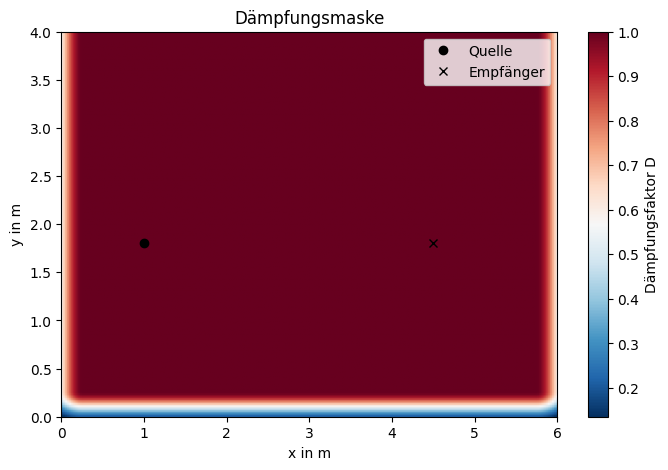

In [12]:
source_pos = (1.0, 1.8)    # Position der Schallquelle in m (x, y)
receiver_pos = (4.5, 1.8)  # Position des Empfangsorts in m (x, y)
f0 = 800.0                 # Mittenfrequenz des Impulses in Hz
t0 = 0.004                 # Zeitpunkt des Quellmaximums in s
damping_width = 10
damping_strength_ceiling = 0.015
damping_strength_walls = 0.005

# 1) Indizes von Quelle und Empfänger bestimmen
# x: Länge (Lx) → Index-Spalte, y: Höhe (Ly) → Index-Zeile
source_j = int(round(source_pos[0] / dx))
source_i = int(round(source_pos[1] / dy))
receiver_j = int(round(receiver_pos[0] / dx))
receiver_i = int(round(receiver_pos[1] / dy))

source_index = (source_i, source_j)
receiver_index = (receiver_i, receiver_j)

# 2) Ricker-Impuls als Quellsignal
tau = np.pi * f0 * (t - t0)
source_signal = (1.0 - 2.0 * tau**2) * np.exp(-tau**2)

# 3) Dämpfungsmaske
damping_mask = np.ones((ny, nx))

# Decke: oberste damping_width Zeilen
for k in range(damping_width):
    d = damping_width - k  # Abstand zur Decke in Gitterpunkten
    D = np.exp(-damping_strength_ceiling * (damping_width - d)**2)
    damping_mask[k, :] *= np.exp(-damping_strength_ceiling * (d**2))

# Seitenwände: links und rechts je damping_width Spalten
for k in range(damping_width):
    d = damping_width - k  # Abstand zur Seitenwand
    factor = np.exp(-damping_strength_walls * (d**2))
    # linke Wand
    damping_mask[:, k] *= factor
    # rechte Wand
    damping_mask[:, -k-1] *= factor

# 4) Visualisierung der Dämpfungsmaske
fig_mask, ax = plt.subplots()
im = ax.imshow(damping_mask, origin="lower",
               extent=[x[0], x[-1], y[0], y[-1]],
               aspect="auto")
plt.colorbar(im, ax=ax, label="Dämpfungsfaktor D")

ax.set_xlabel("x in m")
ax.set_ylabel("y in m")
ax.set_title("Dämpfungsmaske")

# Quelle als Kreis, Empfänger als Kreuz markieren
ax.plot(source_pos[0], source_pos[1], "o", color="k", label="Quelle")
ax.plot(receiver_pos[0], receiver_pos[1], "x", color="k", label="Empfänger")
ax.legend()

In [13]:
# Hier sind Plausibilitaets-Tests:
assert isinstance(source_index, tuple) and len(source_index) == 2
assert isinstance(receiver_index, tuple) and len(receiver_index) == 2
assert source_index == (int(np.argmin(np.abs(y - source_pos[1]))), int(np.argmin(np.abs(x - source_pos[0]))))
assert receiver_index == (int(np.argmin(np.abs(y - receiver_pos[1]))), int(np.argmin(np.abs(x - receiver_pos[0]))))

In [14]:
# Einige weitere Plausibilitaets-Tests:
assert isinstance(source_signal, np.ndarray)
assert source_signal.shape == (nt,)
assert np.max(np.abs(source_signal)) > 0.9
assert isinstance(damping_mask, np.ndarray)

#### 5. Simulationsfunktion

In dieser Aufgabe wird aus den Bausteinen der vorherigen Aufgaben eine Funktion für die vollständige FDTD-Simulation zusammengesetzt. Bisher wurden das Rechengitter, die Zeitschrittweite, der diskrete Laplace-Operator, ein einzelner FDTD-Zeitschritt, die Schallquelle, der Empfangsort und die Dämpfungsmaske vorbereitet. Nun soll daraus eine Funktion entstehen, die die Ausbreitung des Schallimpulses über viele Zeitschritte berechnet.

Schreiben Sie dazu die Funktion `run_simulation(damping_mask, obstacle_mask=None, snapshot_steps=[])`. Die Dämpfungsmaske soll dabei immer angegeben werden, weil die Simulation sonst keine absorbierenden Bereiche enthält und der Impuls unrealistisch lange im Raum verbleibt. Die Funktion soll intern drei Druckfelder verwenden:

- `p_nm1`: Druckfeld aus dem vorletzten Zeitschritt, also $p(t-\Delta t)$, initialisiert mit 0
- `p_n`: Druckfeld aus dem aktuellen Zeitschritt, also $p(t)$, initialisiert mit 0
- `p_np1`: neu berechnetes Druckfeld für den nächsten Zeitschritt, also $p(t+\Delta t)$.

Für jeden Zeitschritt `k` soll die Funktion die folgenden Schritte ausführen:

1. Berechnen Sie mit `fdtd_step(...)` aus `p_nm1` und `p_n` das neue Feld `p_np1`.
2. Addieren Sie den aktuellen Wert des Quellsignals `source_signal[k]` am Gitterpunkt `source_index` zu `p_np1`. Dadurch wird die Schallquelle in die Simulation eingespeist.
3. Falls `obstacle_mask` angegeben ist, setzen Sie die dort markierten Gitterpunkte in `p_np1` und `p_n` auf `0`. `obstacle_mask` ist ein boolesches Array der Form `(ny, nx)`: `True` bedeutet, dass der entsprechende Gitterpunkt zu einem Hindernis gehört, `False` bedeutet freier Raum. Diese Option wird später für die Stellwand verwendet.
4. Multiplizieren Sie `p_np1` und `p_n` in jedem Zeitschritt mit `damping_mask`. Dadurch wird das Feld in den absorbierenden Bereichen abgeschwächt.
5. Speichern Sie den Wert von `p_np1` am Empfangsort `receiver_index` im Array `receiver_signal[k]`.
6. Falls `k` in `snapshot_steps` enthalten ist, speichern Sie mit `p_np1.copy()` eine Kopie des aktuellen Feldes in der Liste `snapshots`.
7. Aktualisieren Sie die Felder für den nächsten Zeitschritt: Aus `p_n` wird `p_nm1`, und aus `p_np1` wird `p_n`.

Wenn keine Hindernismaske übergeben wird, soll `obstacle_mask` als boolesches Array voller `False` angelegt werden. Für `damping_mask` soll es dagegen keinen Ersatzwert in der Funktion geben: Die Maske muss beim Aufruf übergeben werden und hat die Form `(ny, nx)`. Für `snapshot_steps` soll direkt in der Funktionsdefinition die leere Liste `[]` als Default verwendet werden. Die Funktion soll am Ende `receiver_signal` und `snapshots` zurückgeben.


In [15]:
def run_simulation(damping_mask, obstacle_mask=None, snapshot_steps=[]):
    # falls keine Hindernisse gegeben sind
    if obstacle_mask is None:
        obstacle_mask = np.zeros((ny, nx), dtype=bool)

    # Druckfelder initialisieren
    p_nm1 = np.zeros((ny, nx))
    p_n = np.zeros((ny, nx))

    # Empfängersignal und Schnappschüsse
    receiver_signal = np.zeros(nt)
    snapshots = []

    for k in range(nt):
        # 1. neuer FDTD-Zeitschritt
        p_np1 = fdtd_step(p_nm1, p_n, c, dt, dx, dy)

        # 2. Quelle einspeisen
        p_np1[source_index] += source_signal[k]

        # 3. Hindernisse setzen
        p_np1[obstacle_mask] = 0
        p_n[obstacle_mask] = 0

        # 4. Dämpfung anwenden
        p_np1 = p_np1 * damping_mask
        p_n = p_n * damping_mask

        # 5. Signal am Empfänger speichern
        receiver_signal[k] = p_np1[receiver_index]

        # 6. Schnappschüsse speichern
        if k in snapshot_steps:
            snapshots.append(p_np1.copy())

        # 7. Felder aktualisieren
        p_nm1 = p_n
        p_n = p_np1

    return receiver_signal, snapshots


In [17]:
# Hier sind Plausibilitaets-Tests:
assert callable(run_simulation)
assert run_simulation.__defaults__[0] is None
assert run_simulation.__defaults__[1] == []

test_receiver_signal, test_snapshots = run_simulation(
    damping_mask,
    snapshot_steps=[0, nt // 2],
)
assert isinstance(test_receiver_signal, np.ndarray)
assert test_receiver_signal.shape == (nt,)

#### 6. Simulation, Direktschallzeit und Visualisierung des Schallfeldes

Verwenden Sie nun die Funktion `run_simulation(...)`, um die vorbereitete Simulation tatsächlich auszuführen. Dabei sollen in demselben Simulationslauf sowohl das Empfangssignal als auch die Schnappschüsse des Druckfeldes berechnet werden. Die Simulation soll also nur einmal gestartet werden.

_HINWEIS: die Berechnung kann einige Sekunden bis zu einer Minute in Anspruch nehmen_

Legen Sie zuerst die gewünschten Snapshot-Zeitpunkte fest: `6 ms`, `12 ms`, `18 ms` und `36 ms`. Bestimmen Sie daraus die zugehörigen Zeitschritt-Indizes `snapshot_steps`. Rufen Sie anschließend die Simulation für den Raum ohne Stellwand, aber mit der vorbereiteten Dämpfungsmaske und mit diesen Snapshot-Zeitpunkten auf:

```python
receiver_signal, snapshots = run_simulation(damping_mask, snapshot_steps=snapshot_steps)
```

Berechnen Sie dafür zunächst den Abstand `distance` zwischen Schallquelle und Empfangsort. Bestimmen Sie anschließend die erwartete Ankunftszeit des Direktschalls. Der Ricker-Puls ist nicht bei $t=0$, sondern um `t0` zentriert. Deshalb ergibt sich für die erwartete Direktschallzeit

$$
t_\mathrm{direct}=t_0+\frac{r}{c},
$$

wobei $r$ der Abstand zwischen Schallquelle und Empfangsort und $c$ die Schallgeschwindigkeit ist.

Bestimmen Sie aus dem Empfangssignal zusätzlich den Zeitpunkt `t_peak` des größten Ausschlags in einem Suchfenster von $\pm 4\,\mathrm{ms}$ um `t_direct`. Damit wird vermieden, dass spätere Reflexionen mit dem Direktschall verwechselt werden.

Stellen Sie das Quellsignal und das Empfangssignal normiert über der Zeit in Millisekunden dar. Normieren Sie beide Signale jeweils durch ihren größten Absolutwert, damit ihre Formen gut vergleichbar sind. Markieren Sie die erwartete Direktschallzeit `t_direct` als vertikale gestrichelte Linie im Diagramm und geben Sie `t_direct` sowie `t_peak` in Millisekunden aus. 

**Speichern Sie die Figur dieses Diagramms in der Variablen `fig_signal`.**

Ein Schnappschuss ist ein vollständiges Druckfeld zu einem bestimmten Zeitpunkt. Stellen Sie die vier gespeicherten Felder nebeneinander dar und markieren Sie Schallquelle und Empfangsort. Erzeugen Sie dafür mit `plt.subplots` eine einzige Figur mit genau vier nebeneinanderliegenden Teilplots (d.h. einen pro Snapshot-Zeitpunkt, in derselben Reihenfolge wie `snapshot_times`). Markieren Sie in jedem Subplot die Schallquelle mit ax.plot als Kreis ("o") und den Empfangsort als Kreuz ("x"). 

**Speichern Sie diese Figur in der Variablen `fig_snapshots`.**

Die Visualisierung soll zeigen, wie sich der Impuls ausbreitet und wann er ungefähr am Empfangsort ankommt. Achten Sie dabei auf das Vorzeichen des Drucks: Positive und negative Werte gehören beide zur Welle und werden typischerweise mit unterschiedlichen Farben dargestellt.

t_direct [ms]: 14.204081632653061
t_peak   [ms]: 14.379212241329942


C:\Users\mertc\AppData\Local\Temp\ipykernel_29244\3911763413.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


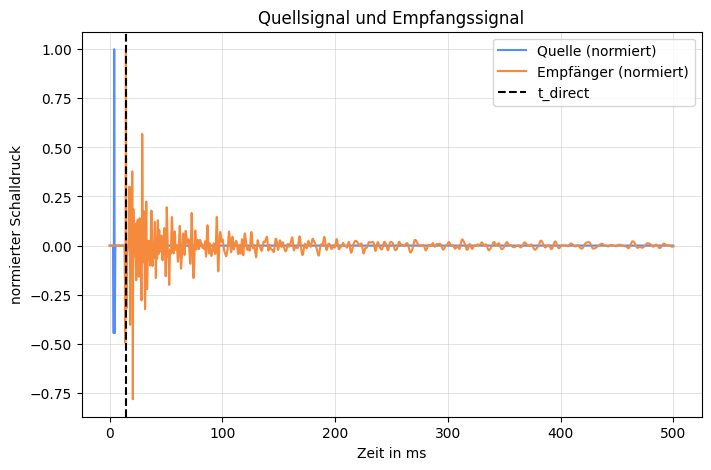

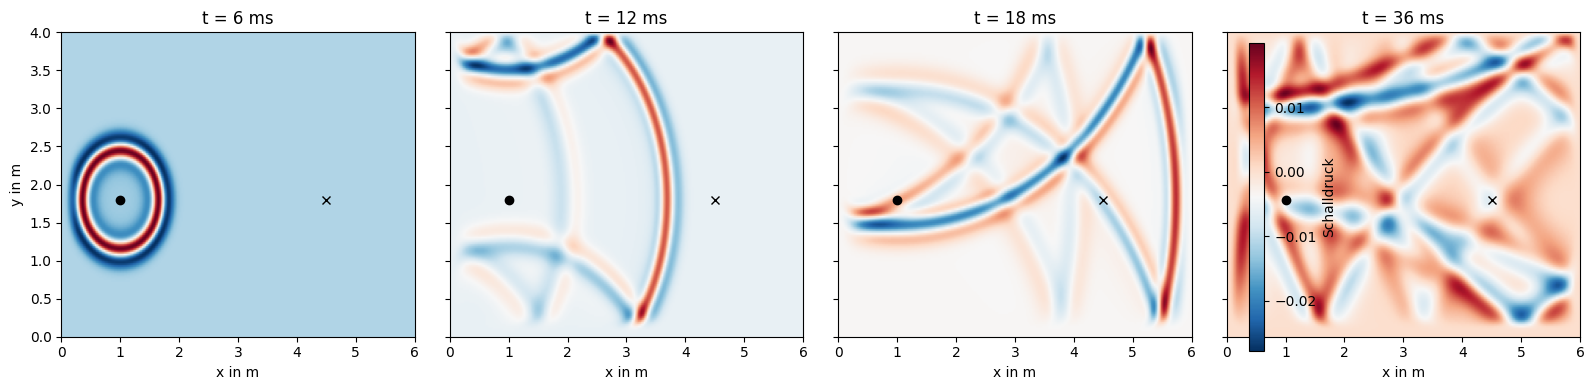

In [18]:
snapshot_times = np.array([0.006, 0.012, 0.018, 0.036])

# 1) Snapshot-Indizes aus Zeiten berechnen
snapshot_steps = (snapshot_times / dt).astype(int)

# 2) Simulation ohne Stellwand starten
receiver_signal, snapshots = run_simulation(damping_mask,
                                            snapshot_steps=list(snapshot_steps))

# 3) Abstand Quelle–Empfänger und erwartete Direktschallzeit
distance = np.sqrt((receiver_pos[0] - source_pos[0])**2 +
                   (receiver_pos[1] - source_pos[1])**2)
t_direct = t0 + distance / c

# 4) Peak im Fenster ±4 ms um t_direct finden
window_half = 0.004  # 4 ms
idx_center = int(round(t_direct / dt))
idx_half = int(round(window_half / dt))
idx_start = max(idx_center - idx_half, 0)
idx_end = min(idx_center + idx_half, nt - 1)

window = receiver_signal[idx_start:idx_end+1]
rel_peak_idx = np.argmax(np.abs(window))      # Index im Fenster
peak_idx = idx_start + rel_peak_idx          # globaler Index
t_peak = t[peak_idx]

print("t_direct [ms]:", t_direct * 1e3)
print("t_peak   [ms]:", t_peak * 1e3)

# 5) Signal-Plot: Quellsignal vs. Empfangssignal (normiert)
source_norm = source_signal / np.max(np.abs(source_signal))
receiver_norm = receiver_signal / np.max(np.abs(receiver_signal))

t_ms = t * 1e3
t_direct_ms = t_direct * 1e3

fig_signal, ax = plt.subplots()
ax.plot(t_ms, source_norm, label="Quelle (normiert)")
ax.plot(t_ms, receiver_norm, label="Empfänger (normiert)")

ax.axvline(t_direct_ms, color="k", linestyle="--", label="t_direct")

ax.set_xlabel("Zeit in ms")
ax.set_ylabel("normierter Schalldruck")
ax.set_title("Quellsignal und Empfangssignal")
ax.legend()
ax.grid(True)

# 6) Schnappschüsse des Schallfeldes
fig_snapshots, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)

for ax, p_snap, t_snap in zip(axes, snapshots, snapshot_times):
    im = ax.imshow(p_snap, origin="lower",
                   extent=[x[0], x[-1], y[0], y[-1]],
                   aspect="auto")
    ax.plot(source_pos[0], source_pos[1], "o", color="k")
    ax.plot(receiver_pos[0], receiver_pos[1], "x", color="k")
    ax.set_title(f"t = {t_snap*1e3:.0f} ms")

fig_snapshots.colorbar(im, ax=axes.ravel().tolist(), label="Schalldruck")
for ax in axes:
    ax.set_xlabel("x in m")
axes[0].set_ylabel("y in m")

plt.tight_layout()


In [19]:
# Hier sind Plausibilitaets-Tests:
assert isinstance(receiver_signal, np.ndarray)
assert receiver_signal.shape == (nt,)

In [20]:
# Einige weitere Plausibilitaets-Tests:
assert np.max(np.abs(receiver_signal)) > 0
assert np.isclose(distance, 3.5, atol=dx)

#### 7. Stellwand einfügen und Pegelminderung bestimmen

Fügen Sie nun eine mobile Stellwand zwischen Schallquelle und Empfangsort ein. Modellieren Sie diese vereinfacht als Bereich, in dem der Schalldruck auf null gesetzt wird. Das ist ein stark vereinfachtes Hindernismodell: Es beschreibt keine genaue Materialeigenschaft, macht aber den Schallschatten hinter der Stellwand sichtbar. Verwenden Sie eine senkrechte Wand bei `x = 3.0 m` mit einer Breite von `0.10 m`, die vom Boden `y = 0.0 m` bis `y = 3.4 m` reicht. In diesem Bereich soll die Maske für das Hindernis den Wert `True` haben.

Führen Sie die Simulation nun erneut aus 

```python
receiver_barrier, snapshots_barrier = run_simulation(
    damping_mask,
    obstacle_mask=obstacle_mask,
    snapshot_steps=snapshot_steps,
)
```

und stellen Sie diesmal beide Impulsantworten (ohne und mit Stellwand) in Millisekunden in einem Diagramm dar. 

**Speichern Sie die Figur dieses Diagramms in der Variablen `fig_barrier_signal`.** 

Stellen Sie außerdem die Snapshots des Schallfeldes für die Simulation mit Stellwand dar. Erzeugen Sie dafür mit `plt.subplots` eine einzige Figur mit genau vier nebeneinanderliegenden Teilplots (d.h. einen pro Snapshot-Zeitpunkt, in derselben Reihenfolge wie `snapshot_times`). Markieren Sie in jedem Subplot die Schallquelle mit ax.plot als Kreis ("o") und den Empfangsort als Kreuz ("x").  

**Speichern Sie diese Figur in der Variablen `fig_barrier_snapshots`.**

Bestimmen Sie zum Abschluss die Pegelminderung anhand der gesamten diskreten Signalenergie am Empfangsort. Dazu wird nicht nur der erste Peak betrachtet, sondern das gesamte Signal während der Simulationszeit.

$$
\Delta L = 10\log_{10}\left(\frac{E_\mathrm{ohne}}{E_\mathrm{mit}}\right)\,\mathrm{dB}
$$
wobei
$$
E = \sum_k p_k^2
$$
gilt.

Speichern Sie die Pegelminderung in `delta_L`. Ein positiver Wert bedeutet, dass am Empfangsort mit Stellwand weniger Schallenergie ankommt als ohne Stellwand.

E_ohne = 0.14747322901471316
E_mit  = 0.028728274031515608
ΔL     = 7.1040365473148395 dB


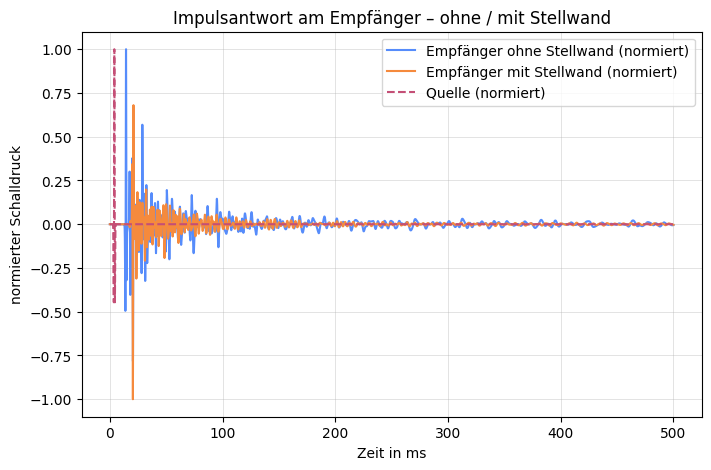

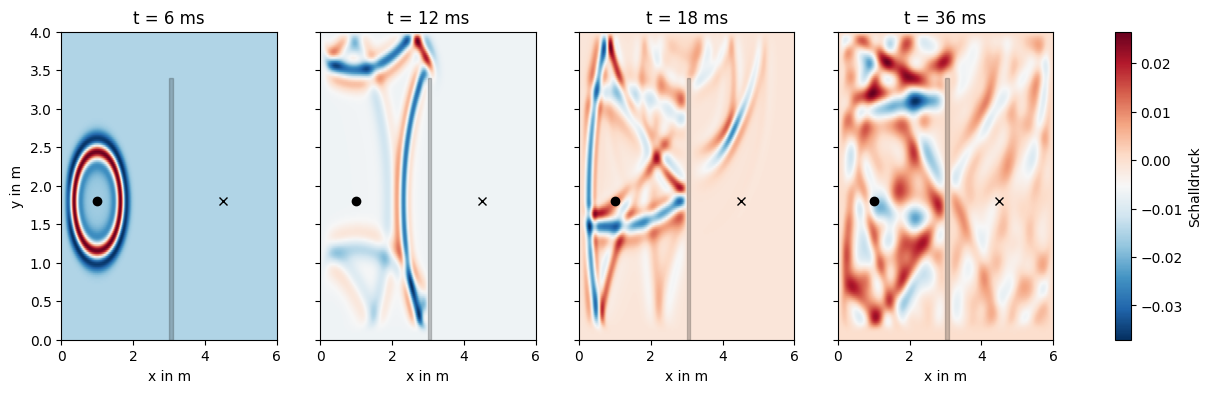

In [21]:
# 1) Hindernismaske (Stellwand) anlegen:
# senkrechte Wand bei x = 3.0 m, Breite 0.10 m, y von 0.0 m bis 3.4 m

obstacle_mask = np.zeros((ny, nx), dtype=bool)

x_min = 3.0
x_max = 3.1  # 3.0 m + 0.10 m
y_min = 0.0
y_max = 3.4

# logische Maske für alle Gitterpunkte im Wand-Bereich
mask_x = (x >= x_min) & (x <= x_max)
mask_y = (y >= y_min) & (y <= y_max)

# in 2D kombinieren
for i in range(ny):
    if mask_y[i]:
        obstacle_mask[i, mask_x] = True

# 2) Simulation mit Stellwand
receiver_barrier, snapshots_barrier = run_simulation(
    damping_mask,
    obstacle_mask=obstacle_mask,
    snapshot_steps=list(snapshot_steps),
)

# 3) Impulsantworten ohne / mit Wand in einem Diagramm (ms, normiert)

receiver_norm_free = receiver_signal / np.max(np.abs(receiver_signal))
receiver_norm_barrier = receiver_barrier / np.max(np.abs(receiver_barrier))
source_norm = source_signal / np.max(np.abs(source_signal))

t_ms = t * 1e3

fig_barrier_signal, ax = plt.subplots()
ax.plot(t_ms, receiver_norm_free, label="Empfänger ohne Stellwand (normiert)")
ax.plot(t_ms, receiver_norm_barrier, label="Empfänger mit Stellwand (normiert)")
ax.plot(t_ms, source_norm, "--", label="Quelle (normiert)")

ax.set_xlabel("Zeit in ms")
ax.set_ylabel("normierter Schalldruck")
ax.set_title("Impulsantwort am Empfänger – ohne / mit Stellwand")
ax.legend()
ax.grid(True)

# 4) Schnappschüsse des Schallfeldes mit Stellwand

fig_barrier_snapshots, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)

for ax, p_snap, t_snap in zip(axes, snapshots_barrier, snapshot_times):
    im = ax.imshow(p_snap, origin="lower",
                   extent=[x[0], x[-1], y[0], y[-1]],
                   aspect="auto")
    # Stellwand als schwarze Linie anzeigen (optional, aber hilfreich)
    ax.axvspan(x_min, x_max, ymin=0.0, ymax=y_max / Ly,
               color="k", alpha=0.2)
    ax.plot(source_pos[0], source_pos[1], "o", color="k")
    ax.plot(receiver_pos[0], receiver_pos[1], "x", color="k")
    ax.set_title(f"t = {t_snap * 1e3:.0f} ms")

fig_barrier_snapshots.colorbar(im, ax=axes.ravel().tolist(), label="Schalldruck")
for ax in axes:
    ax.set_xlabel("x in m")
axes[0].set_ylabel("y in m")

# 5) Pegelminderung aus Gesamtenergie berechnen
# E = Sum_k p_k^2  (für komplettes Signal)

E_ohne = np.sum(receiver_signal ** 2)
E_mit = np.sum(receiver_barrier ** 2)

delta_L = 10.0 * np.log10(E_ohne / E_mit)

print("E_ohne =", E_ohne)
print("E_mit  =", E_mit)
print("ΔL     =", delta_L, "dB")

In [22]:
# Hier sind Plausibilitaets-Tests:
assert isinstance(obstacle_mask, np.ndarray)
assert obstacle_mask.shape == (ny, nx)

In [24]:
# Einige weitere Plausibilitaets-Tests:
assert obstacle_mask.dtype == bool
assert np.any(obstacle_mask)

#### Ausblick

Das Modell ist bewusst kompakt. Für realistischere Simulationen wären frequenzabhängige Absorption, genauere Randbedingungen, dreidimensionale Geometrien und eine feinere Modellierung der Stellwand nötig. Trotzdem lassen sich mit dieser einfachen FDTD-Simulation bereits zentrale Effekte beobachten: Laufzeit, Reflexion, Beugung und eine quantitative Pegelminderung hinter einem Hindernis.
